# NB13 — Visual Anomaly Detection: PatchCore-lite on Synthetic Surfaces (R19, R20)
Sandbox path: synthetic textured surfaces with injected defects (extends the
synthetic-injector asset), patch-feature kNN memory bank ("PatchCore-lite" —
the same memory-bank principle as PatchCore, classical features instead of a
CNN backbone). Workstation path (guarded): anomalib PatchCore on real MVTec AD.
Gate: image-AUROC ≥ 0.95. Conversion target: `aip_vision/anomaly.py`.

In [1]:
import importlib.util
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter, sobel
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors

DATA = Path("../../data")
(DATA / "interim").mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)
IMG = 128

## 1. Synthetic surface generator (shared by NB13–NB15 via this module pattern)

In [2]:
def base_texture(seed):
    r = np.random.default_rng(seed)
    tex = gaussian_filter(r.normal(0, 1, (IMG, IMG)), 3)
    yy, xx = np.mgrid[0:IMG, 0:IMG]
    tex += 0.3 * np.sin(xx / 6.0 + r.uniform(0, 6))          # brushed-metal stripes
    tex = (tex - tex.min()) / (tex.max() - tex.min())
    return 0.35 + 0.3 * tex                                   # mid-grey surface


def inject_defect(img, kind, r):
    """Returns (image, tight bbox[x0,y0,x1,y1] of actually changed pixels)."""
    im = img.copy()
    if kind == "scratch":
        x0, y0 = r.integers(15, IMG - 60, 2)
        L, ang = r.integers(35, 60), r.uniform(0, np.pi)
        xs = (x0 + np.cos(ang) * np.arange(L)).astype(int)
        ys = (y0 + np.sin(ang) * np.arange(L)).astype(int)
        for dx in (-1, 0, 1):
            im[np.clip(ys + dx, 0, IMG - 1), np.clip(xs, 0, IMG - 1)] -= 0.28
        bbox = None  # computed from change mask below
    elif kind == "blob":
        cx, cy = r.integers(25, IMG - 25, 2)
        rad = r.integers(6, 12)
        yy, xx = np.mgrid[0:IMG, 0:IMG]
        mask = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * rad**2)))
        im += 0.35 * mask
        bbox = None
    else:  # pits
        cx, cy = r.integers(25, IMG - 25, 2)
        for _ in range(r.integers(6, 12)):
            px, py = cx + r.integers(-10, 10), cy + r.integers(-10, 10)
            im[max(py - 1, 0):py + 2, max(px - 1, 0):px + 2] -= 0.3
        bbox = None
    im = np.clip(im, 0, 1)
    ys, xs = np.where(np.abs(im - img) > 0.05)
    bbox = [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]
    return im, bbox


def make_anomaly_set(category_seed=0, n_good_train=40, n_good_test=15, n_bad_test=15):
    train = [base_texture(category_seed * 1000 + i) for i in range(n_good_train)]
    test, labels = [], []
    for i in range(n_good_test):
        test.append(base_texture(category_seed * 1000 + 500 + i)); labels.append(0)
    kinds = ["scratch", "blob", "pits"]
    for i in range(n_bad_test):
        img = base_texture(category_seed * 1000 + 800 + i)
        img, _ = inject_defect(img, kinds[i % 3], np.random.default_rng(900 + i))
        test.append(img); labels.append(1)
    return train, test, np.array(labels)

## 2. PatchCore-lite: patch features → kNN memory bank → image score

In [3]:
PATCH, STRIDE = 16, 8

def patch_features(img):
    gm = np.hypot(sobel(img, 0), sobel(img, 1))
    feats = []
    for y in range(0, IMG - PATCH + 1, STRIDE):
        for x in range(0, IMG - PATCH + 1, STRIDE):
            p, g = img[y:y + PATCH, x:x + PATCH], gm[y:y + PATCH, x:x + PATCH]
            feats.append([p.mean(), p.std(), p.min(), p.max(),
                          g.mean(), g.std(), np.percentile(p, 25), np.percentile(p, 75)])
    return np.array(feats)


class PatchCoreLite:
    def fit(self, train_imgs):
        bank = np.vstack([patch_features(im) for im in train_imgs])
        self.nn = NearestNeighbors(n_neighbors=1).fit(bank)
        return self

    def image_score(self, img):
        d, _ = self.nn.kneighbors(patch_features(img))
        return float(np.percentile(d, 99))

model = PatchCoreLite()
train, test, y = make_anomaly_set(category_seed=0)
model.fit(train)
scores = np.array([model.image_score(im) for im in test])
auroc = roc_auc_score(y, scores)
print(f"category-0 image-AUROC: {auroc:.3f}")
assert auroc >= 0.95, "AUROC below gate"

category-0 image-AUROC: 1.000


## 3. Demo heatmap + workstation path

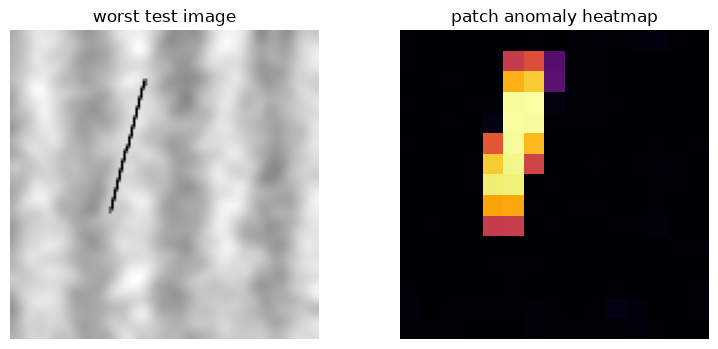

SKIP anomalib (workstation): uv add anomalib; datasets: MVTec AD
NB13 complete.


In [4]:
bad = test[int(np.argmax(scores))]
d, _ = model.nn.kneighbors(patch_features(bad))
side = (IMG - PATCH) // STRIDE + 1
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
ax[0].imshow(bad, cmap="gray"); ax[0].set_title("worst test image")
ax[1].imshow(d.reshape(side, side), cmap="inferno"); ax[1].set_title("patch anomaly heatmap")
[a.axis("off") for a in ax]
plt.tight_layout(); plt.savefig(DATA / "interim/nb13_heatmap.png", dpi=110); plt.show()

if importlib.util.find_spec("anomalib"):
    print("anomalib present → run PatchCore on real MVTec (see Phase 3 SOP runbook)")
else:
    print("SKIP anomalib (workstation): uv add anomalib; datasets: MVTec AD")

json.dump({"category0_auroc": round(float(auroc), 4), "backend": "patchcore-lite"},
          open(DATA / "processed/nb13_anomaly.json", "w"))
print("NB13 complete.")